# Python for Data Analysis — Learning Notes*Personal notes from an introductory course on Python, NumPy, pandas, and data visualization with Matplotlib and Seaborn.*---## About this notebookThese are structured notes I took while learning the Python data-analysis stack. They cover the fundamentals I used as a foundation before moving on to my machine learning projects. Two small public datasets are used for practice:- **IGN video-game reviews** — for practicing pandas filtering, grouping, and categorical plots.- **Pokémon stats** — for practicing descriptive statistics and distribution plots.The datasets are freely available on Kaggle. To run this notebook, upload the CSV files to your Colab environment (or update the paths).**Topics covered**1. NumPy basics — array creation and random number generation2. Loading and exploring data with pandas3. Selecting, slicing, and filtering DataFrames4. Descriptive statistics5. Visualizing categorical data with Seaborn6. Distribution and comparison plots---

## 1. NumPy basicsNumPy is the foundation of the Python scientific stack. Before doing anything else, we import it.

In [ ]:
import numpy as np

### 1.1 Generating random numbers`np.random.seed(n)` fixes the random state so results are reproducible — an important habit in any experimental work.`np.random.random(n)` returns `n` random floats in `[0, 1)`.

In [ ]:
# Set a random seed for reproducibility
np.random.seed(10)

# Generate 10 random floats in [0, 1)
d = np.random.random(10)
print(d)

[0.77132064 0.02075195 0.63364823 0.74880388 0.49850701 0.22479665
 0.19806286 0.76053071 0.16911084 0.08833981]


`np.random.randint(low, high, size)` returns random integers in `[low, high)`.

In [ ]:
np.random.seed(10)
val = np.random.randint(low=10, high=20, size=30)
print(val)

[19 14 10 11 19 10 11 18 19 10 18 16 14 13 10 14 16 18 11 18 14 11 13 16
 15 13 19 16 19 11]


To generate random floats in an arbitrary range `[a, b)`, use the transformation `a + (b - a) * random()`.

In [ ]:
# Random floats between 10 and 20
val = 10 + (20 - 10) * np.random.random(20)
print(val)

[16.17766978 15.13138243 16.50397182 16.01038953 18.05223197 15.21647152
 19.08648881 13.19236089 10.90459349 13.00700057 11.13984362 18.28681326
 10.46896319 16.26287148 15.47586156 18.19286996 11.9894754  18.56850302
 13.51652639 17.54647692]


### 1.2 Creating arrays with fixed values

In [ ]:
# Array of zeros
v = np.zeros(10)

# Array of ones
f = np.ones(10)

# Array filled with a constant integer
t = np.full(10, 20)

print(v)
print(f)
print(t)

### 1.3 Array indexing

In [ ]:
np.random.seed(10)
val = np.random.random(20)
print(val)

---## 2. Loading and exploring data with pandasNow we move from raw arrays to structured tabular data using pandas. For this section I use the **IGN video-game reviews dataset**, which contains scores and metadata for thousands of games.- `pd.read_csv(path)` loads a CSV file into a DataFrame.- `data.shape` returns `(rows, columns)`.- `data.head()` shows the first 5 rows; `data.tail()` shows the last 5.- `data.info()` gives a schema-level summary.

In [ ]:
import matplotlib.pyplot as plt   # data visualization
import numpy as np                # numerical operations
import pandas as pd               # tabular data analysis

# Path to the dataset — update this to wherever you have the file
path = '/content/ign.csv'

# Load the dataset
data = pd.read_csv(path)
print(type(data))
print('Shape:', data.shape)   # (rows, columns)
data.head()

<class 'pandas.core.frame.DataFrame'>
(18625, 10)


,score_phrase,title,url,platform,score,genre,editors_choice,release_year,release_month,release_day
0,Amazing,LittleBigPlanet PS Vita,/games/littlebigplanet-vita/vita-98907,PlayStation Vita,9.0,Platformer,Y,2012,9,12
1,Amazing,LittleBigPlanet PS Vita -- Marvel Super Hero E...,/games/littlebigplanet-ps-vita-marvel-super-he...,PlayStation Vita,9.0,Platformer,Y,2012,9,12
2,Great,Splice: Tree of Life,/games/splice/ipad-141070,iPad,8.5,Puzzle,N,2012,9,12
3,Great,NHL 13,/games/nhl-13/xbox-360-128182,Xbox 360,8.5,Sports,N,2012,9,11
4,Great,NHL 13,/games/nhl-13/ps3-128181,PlayStation 3,8.5,Sports,N,2012,9,11


In [ ]:
data.tail()   # last 5 rows

,score_phrase,title,url,platform,score,genre,editors_choice,release_year,release_month,release_day
18620,Good,Tokyo Mirage Sessions #FE,/games/fire-emblem-x-shin-megami-tensei/wii-u-...,Wii U,7.6,RPG,N,2016,6,29
18621,Amazing,LEGO Star Wars: The Force Awakens,/games/lego-star-wars-the-force-awakens/ps4-20...,PlayStation 4,9.0,"Action, Adventure",Y,2016,6,29
18622,Mediocre,Star Ocean: Integrity and Faithlessness,/games/star-ocean-5/ps4-20035681,PlayStation 4,5.8,RPG,N,2016,6,28
18623,Masterpiece,Inside,/games/inside-playdead/xbox-one-121435,Xbox One,10.0,Adventure,Y,2016,6,28
18624,Masterpiece,Inside,/games/inside-playdead/pc-20055740,PC,10.0,Adventure,Y,2016,6,28


### 2.1 Selecting columns and rowsYou can pass a list of column names to select multiple columns.

In [ ]:
# Select specific columns
newData = data[['platform', 'score_phrase', 'release_year']]
newData

,platform,score_phrase,release_year
0,PlayStation Vita,Amazing,2012
1,PlayStation Vita,Amazing,2012
2,iPad,Great,2012
3,Xbox 360,Great,2012
4,PlayStation 3,Great,2012
...,...,...,...
18620,Wii U,Good,2016
18621,PlayStation 4,Amazing,2016
18622,PlayStation 4,Mediocre,2016
18623,Xbox One,Masterpiece,2016


`.loc[]` is label-based indexing. `data.loc[4:9, :]` selects rows 4 through 9 (inclusive) and all columns.

In [ ]:
data1 = data.loc[4:9, :]
data1

,score_phrase,title,url,platform,score,genre,editors_choice,release_year,release_month,release_day
4,Great,NHL 13,/games/nhl-13/ps3-128181,PlayStation 3,8.5,Sports,N,2012,9,11
5,Good,Total War Battles: Shogun,/games/total-war-battles-shogun/mac-142565,Macintosh,7.0,Strategy,N,2012,9,11
6,Awful,Double Dragon: Neon,/games/double-dragon-neon/xbox-360-131320,Xbox 360,3.0,Fighting,N,2012,9,11
7,Amazing,Guild Wars 2,/games/guild-wars-2/pc-896298,PC,9.0,RPG,Y,2012,9,11
8,Awful,Double Dragon: Neon,/games/double-dragon-neon/ps3-131321,PlayStation 3,3.0,Fighting,N,2012,9,11
9,Good,Total War Battles: Shogun,/games/total-war-battles-shogun/pc-142564,PC,7.0,Strategy,N,2012,9,11


### 2.2 Schema summary

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18625 entries, 0 to 18624
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   score_phrase    18625 non-null  object 
 1   title           18625 non-null  object 
 2   url             18625 non-null  object 
 3   platform        18625 non-null  object 
 4   score           18625 non-null  float64
 5   genre           18589 non-null  object 
 6   editors_choice  18625 non-null  object 
 7   release_year    18625 non-null  int64  
 8   release_month   18625 non-null  int64  
 9   release_day     18625 non-null  int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 1.4+ MB


---## 3. Descriptive statisticsBasic aggregations on a numeric column.

In [ ]:
score_ign = data['score']

min_score = score_ign.min()
max_score = score_ign.max()
avg_score = score_ign.mean()

print('Max score:', max_score)
print('Min score:', min_score)
print('Avg score:', round(avg_score, 2))

<Max score  10.0
Min score  0.5
Avg score  6.950459060402685


### 3.1 Unique values and value counts- `.unique()` returns the distinct values in a column.- `.value_counts()` returns how often each unique value appears — useful for spotting class imbalance.

In [ ]:
# Unique release years
year = data['release_year'].unique()
print(year)
print('Number of unique years:', len(year))

# Unique score phrases
platform = data['score_phrase'].unique()
print(platform)
print('Number of unique score phrases:', len(platform))

[2012 2013 1996 1970 1997 1998 1999 2000 2001 2002 2003 2004 2005 2006
 2007 2008 2009 2010 2011 2014 2015 2016]
22
['Amazing' 'Great' 'Good' 'Awful' 'Okay' 'Mediocre' 'Bad' 'Painful'
 'Unbearable' 'Disaster' 'Masterpiece']
11


In [ ]:
num_of_games_year = data['release_year'].value_counts()
print(num_of_games_year)

print('*' * 30)

num_of_games_score_phrase = data['score_phrase'].value_counts()
print(num_of_games_score_phrase)

print('*' * 30)

num_of_games_platform = data['platform'].value_counts()
print(num_of_games_platform)

release_year
2008    1915
2009    1687
2007    1610
2010    1363
2006    1208
2005    1088
2011    1073
2000    1045
2004     997
2003     969
2002     936
1999     775
2012     753
2013     696
2001     688
2014     537
2015     365
1998     339
2016     226
1997     205
1996     149
1970       1
Name: count, dtype: int64


score_phrase
Great          4773
Good           4741
Okay           2945
Mediocre       1959
Amazing        1804
Bad            1269
Awful           664
Painful         340
Unbearable       72
Masterpiece      55
Disaster          3
Name: count, dtype: int64
platform
PC                      3370
PlayStation 2           1686
Xbox 360                1631
Wii                     1366
PlayStation 3           1356
Nintendo DS             1045
PlayStation              952
Wireless                 910
iPhone                   842
Xbox                     821
PlayStation Portable     633
Game Boy Advance         623
GameCube                 509
Game Boy Color           356

---## 4. Visualization with SeabornSeaborn is a high-level statistical plotting library built on top of Matplotlib. It works well with pandas DataFrames.### 4.1 Count plots

Text(0.5, 1.0, 'count plot of the score phrase')

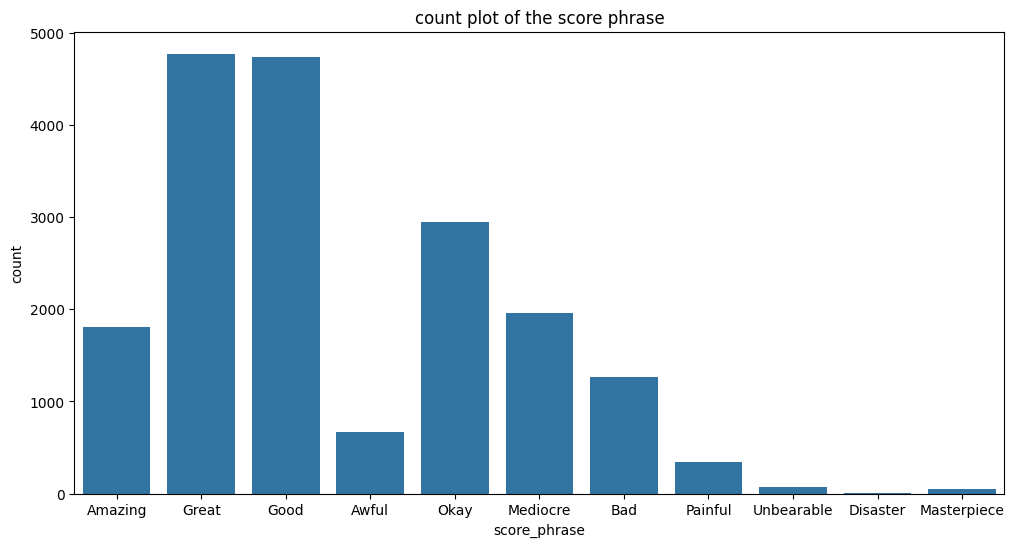

In [ ]:
import seaborn as sns

plt.figure(1, figsize=(12, 6))
sns.countplot(data=data, x='score_phrase')
plt.title('Count plot of score phrase')
plt.show()

We can add a `hue` argument to break each bar down by a second categorical variable — here, whether the game was an editor's choice.

Text(0.5, 1.0, 'count plot of the score phrase')

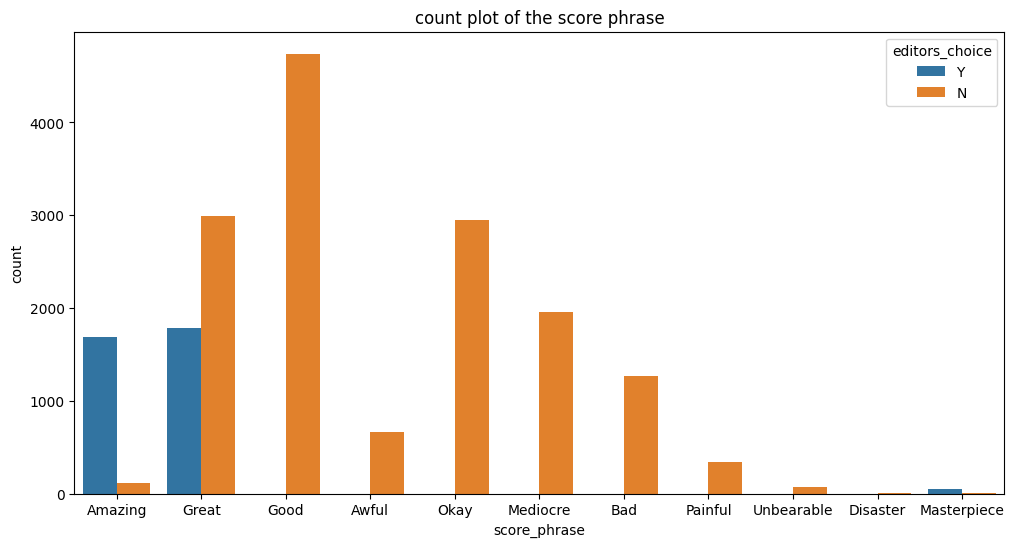

In [ ]:
plt.figure(1, figsize=(12, 6))
sns.countplot(data=data, x='score_phrase', hue='editors_choice')
plt.title('Count plot of score phrase, split by editor\'s choice')
plt.show()

### 4.2 Adding value labels on barsWe can iterate over `ax.containers` and use `ax.bar_label()` to annotate the bars with their counts.

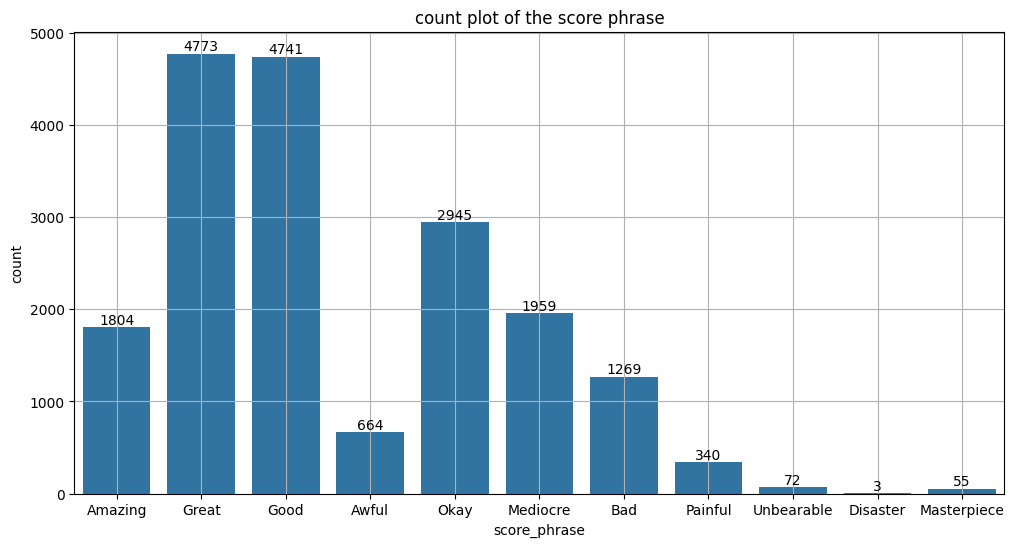

In [ ]:
plt.figure(1, figsize=(12, 6))
ax = sns.countplot(data=data, x='score_phrase')

for container in ax.containers:
    ax.bar_label(container)

plt.title('Count plot of score phrase (with labels)')
plt.grid(True)
plt.show()

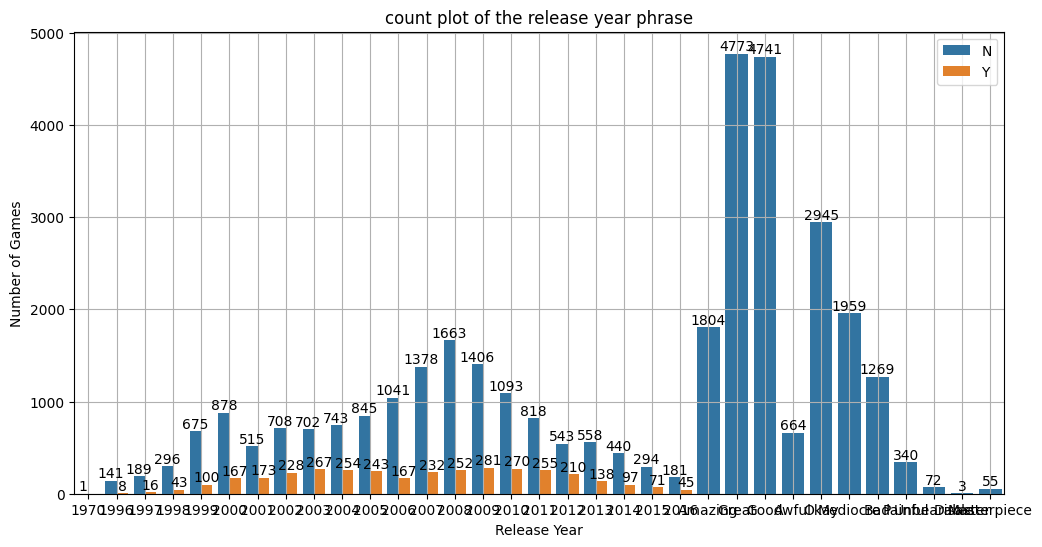

In [ ]:
plt.figure(1, figsize=(12, 6))
ax = sns.countplot(data=data, x='release_year')

for container in ax.containers:
    ax.bar_label(container)

plt.title('Number of games by release year')
plt.xlabel('Release year')
plt.ylabel('Number of games')
plt.grid(True)
plt.show()

---## 5. Filtering data with boolean indexingBoolean masks are one of the most useful patterns in pandas: build a `True`/`False` array based on a condition, then use it to index the DataFrame.

**Question:** What are the titles and platforms of games rated *Disaster*?

In [ ]:
index = data['score_phrase'] == 'Disaster'   # boolean mask
newData = data[index]                        # keep only rows where the mask is True
newData[['title', 'platform', 'score_phrase']]

,title,platform,score_phrase
890,Extreme PaintBrawl,PC,Disaster
5242,Looney Tunes: Back in Action: Zany Race,Wireless,Disaster
12513,Action Girlz Racing,Wii,Disaster


**Question:** How many PC games are rated *Great*?We combine two conditions with the bitwise `&` operator. Each condition must be wrapped in parentheses.

In [ ]:
ind = (data['platform'] == 'PC') & (data['score_phrase'] == 'Great')
newData = data[ind]
print('Total number of Great PC games:', newData.shape[0])

total number of great PC games are:  967


---## 6. Descriptive statistics and distributions (Pokémon dataset)Switching to the Pokémon stats dataset to practice `.describe()`, distribution plots, and comparison plots.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

path = '/content/Pokemon.csv'
data = pd.read_csv(path)
print('Shape:', data.shape)
data.head()

(800, 13)


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


### 6.1 Dropping columns`.drop()` returns a new DataFrame by default. Set `inplace=True` to modify the original.

In [ ]:
# inplace=False: returns a new DataFrame, original is unchanged
newdata = data.drop('#', axis=1, inplace=False)
print('newdata shape:', newdata.shape)
print('data shape:   ', data.shape)

(800, 12)
(800, 13)


In [ ]:
# inplace=True: modifies data directly
data.drop('#', axis=1, inplace=True)
data.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


### 6.2 `.describe()`Returns count, mean, std, min, quartiles, and max for each numeric column.

In [ ]:
res = data.describe()
res = res.astype(int)   # cast to integers for a cleaner display
res

,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800,800,800,800,800,800,800,800
mean,435,69,79,73,72,71,68,3
std,119,25,32,31,32,27,29,1
min,180,1,5,5,10,20,5,1
25%,330,50,55,50,49,50,45,2
50%,450,65,75,70,65,70,65,3
75%,515,80,100,90,95,90,90,5
max,780,255,190,230,194,230,180,6


In [ ]:
res_speed = data['Speed'].describe().astype(int)
res_speed

count    800
mean      68
std       29
min        5
25%       45
50%       65
75%       90
max      180
Name: Speed, dtype: int64

### 6.3 Distribution plots

Text(0.5, 1.0, 'Attack distribution plot')

<Figure size 640x480 with 0 Axes>

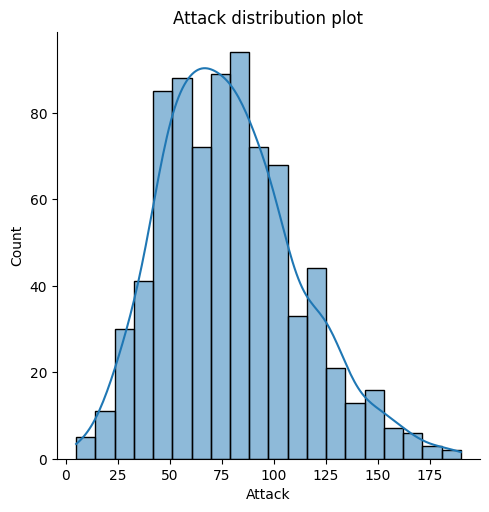

In [ ]:
sns.displot(data=data, x='Attack', kde=True)
plt.title('Attack distribution')
plt.show()

### 6.4 Box plotsBox plots summarize the median, quartiles, and outliers of a numeric variable.

Text(0.5, 1.0, 'Attack box plot analysis')

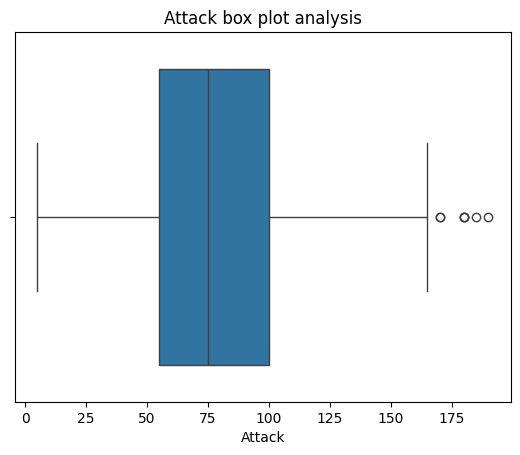

In [ ]:
plt.figure(1)
sns.boxplot(data=data, x='Attack')
plt.title('Attack — box plot')
plt.show()

Text(0.5, 1.0, 'box plot analysis')

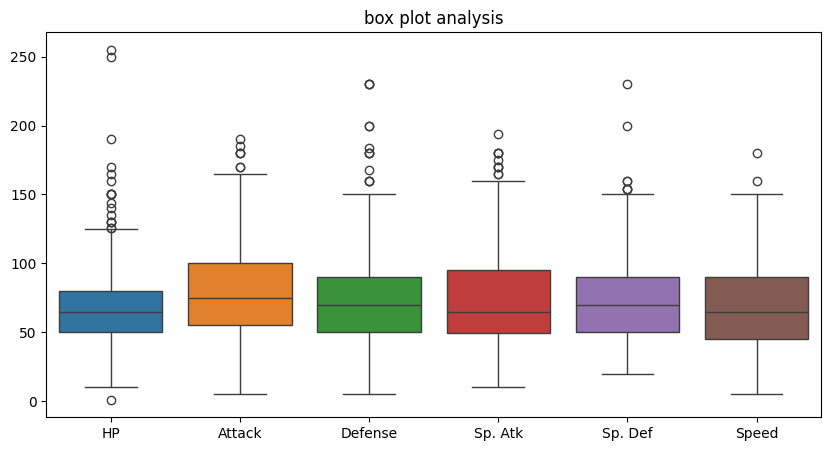

In [ ]:
# Compare the distributions of all six stat columns side by side
newdata = data[['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']]

plt.figure(1, figsize=(10, 5))
sns.boxplot(data=newdata)
plt.title('Distribution of Pokémon stats')
plt.show()

### 6.5 Comparison across generations`sns.barplot` shows the mean of a numeric variable (`y`) for each category (`x`), with an optional `hue` for a second split. Here we compare stats across Pokémon generations, split by whether they are Legendary.

<Axes: xlabel='Generation', ylabel='Defense'>

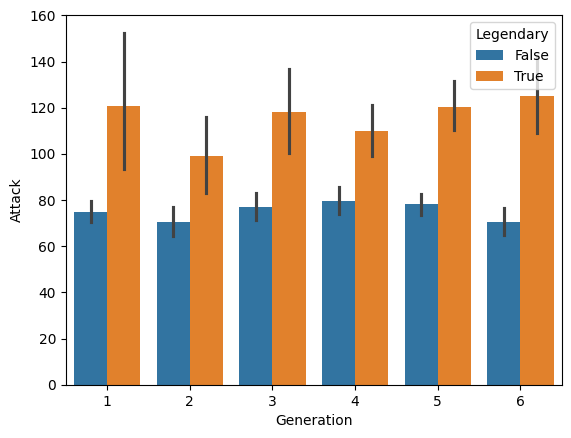

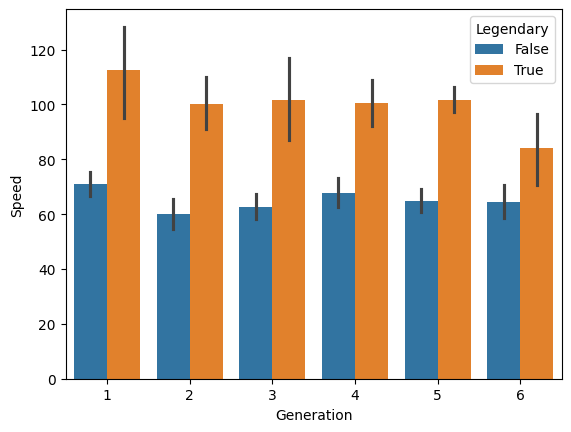

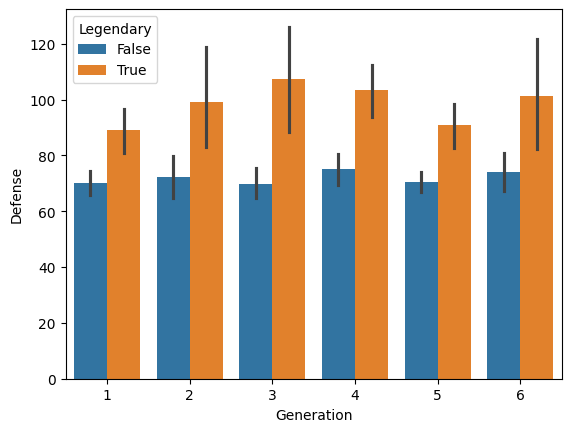

In [ ]:
plt.figure(1)
sns.barplot(data=data, x='Generation', y='Attack', hue='Legendary')
plt.title('Attack by generation (Legendary vs. non-Legendary)')

plt.figure(2)
sns.barplot(data=data, x='Generation', y='Speed', hue='Legendary')
plt.title('Speed by generation')

plt.figure(3)
sns.barplot(data=data, x='Generation', y='Defense', hue='Legendary')
plt.title('Defense by generation')

plt.show()

### 6.6 Multiple subplots`plt.subplot(rows, cols, index)` lets us arrange several plots in a grid.

<Axes: xlabel='Sp. Atk', ylabel='Count'>

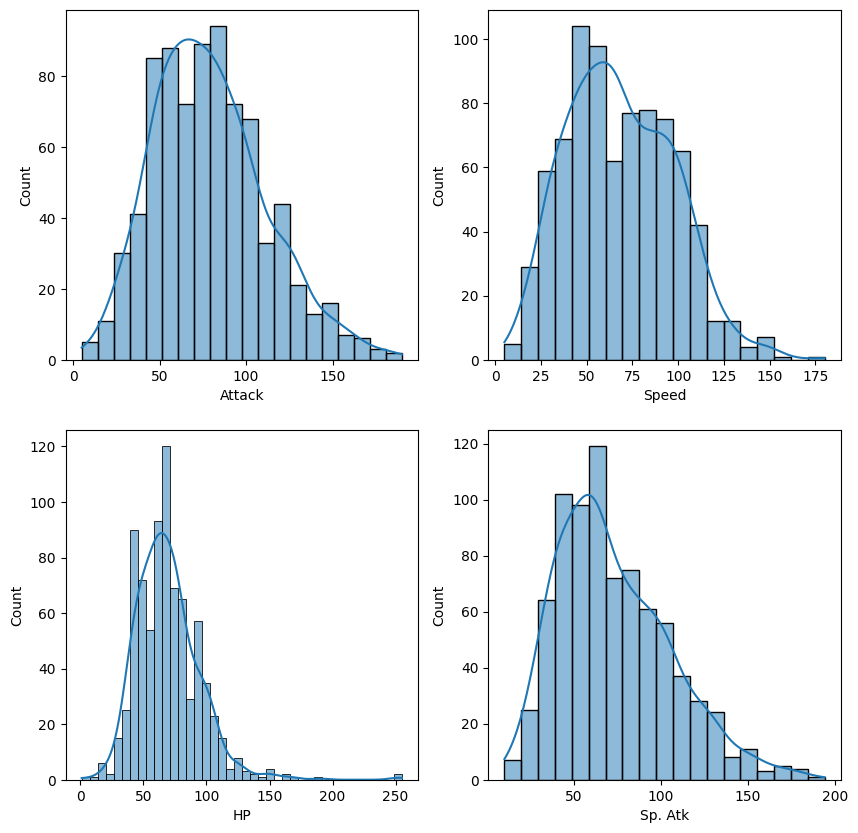

In [ ]:
plt.figure(1, figsize=(10, 10))

plt.subplot(2, 2, 1)
sns.histplot(data=data, x='Attack', kde=True)

plt.subplot(2, 2, 2)
sns.histplot(data=data, x='Speed', kde=True)

plt.subplot(2, 2, 3)
sns.histplot(data=data, x='HP', kde=True)

plt.subplot(2, 2, 4)
sns.histplot(data=data, x='Sp. Atk', kde=True)

plt.tight_layout()
plt.show()

---## SummaryThese notes covered the core Python data-analysis workflow: loading data with pandas, exploring it with `.info()`, `.describe()`, `.unique()`, and `.value_counts()`, filtering with boolean masks, and visualizing with Matplotlib and Seaborn.**Next in my learning path:** applied machine learning — see my other repositories for supervised learning projects, model evaluation, and deep learning experiments.---*Author: [Your Name] · [Your GitHub] · [Your Email]*